# PART 5. EDA (탐색적 데이터 분석)

## 📋 한눈에 보기

**작업 흐름**
```
1. 통합 데이터 불러오기
2. 집계 단위 맞추기 (주문·상품·결제)
3. 기본 EDA (상태·매출·카테고리·리뷰)
4. 분석 기간 정하기
5. 인사이트 1~10 확인
6. 인사이트를 실행으로 정리
```

| 항목 | 내용 |
|---|---|
| 핵심 질문 | 데이터에서 어떤 비즈니스 패턴이 보일까? |
| 사용 데이터 | `olist_master_data.csv` (분석 기간 2017-01-05 ~ 2018-08-29, 배송 완료) |
| 결과물 | 인사이트 10가지 + 실행 제안 (→ PART 6~10의 문제 정의) |

**🎯 핵심 (꼭 가져갈 것)**
- **무엇을 세는지**(주문·상품·결제)에 맞는 단위로 집계해야 숫자가 맞습니다.
- 그래프가 급락해도 실제 하락이 아닐 수 있습니다(데이터 수집 종료). 원인을 꼭 확인합니다.

**💡 인사이트 (이 파트에서 확인한 사실)**
- 고객의 97.0%가 한 번만 구매 → 고객 기반 추천·고객 이탈 예측이 어렵습니다. (→ PART 6, 9의 문제 재정의)
- 배송이 늦으면 평균 리뷰가 4.30 → 2.57로 떨어집니다. (→ PART 7, 8)
- 성장은 객단가가 아니라 주문 수(2.40배)에서 왔습니다. (→ PART 6 추천으로 객단가 높이기)

---

## 수업 목표
- 그래프와 집계로 매출 추이, 리뷰, 인기 카테고리 패턴을 확인합니다.
- **무엇을 세는지(주문·상품·결제)에 맞는 단위**로 집계하는 법을 익힙니다.
- 데이터에서 **비즈니스 인사이트 10가지**를 직접 숫자로 확인합니다.
- EDA는 "정답을 내는 과정"이 아니라 "데이터를 이해하는 과정"입니다.

## 수업 진행 포인트
| 구분 | 설명 |
|---|---|
| 데이터 관점 | 숫자보다 그래프로 전체 흐름을 먼저 봅니다. |
| 코드 관점 | groupby, value_counts, plot 사용법을 익힙니다. |
| AI 관점 | EDA 없이 AI를 바로 적용하면 잘못된 모델이 만들어집니다. |

In [1]:
# 셀 1. Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 셀 2. 라이브러리 불러오기

# 그래프 한글 깨짐 방지 (Colab에는 한글 폰트가 없어서 □□□로 표시됨)
!pip install -q koreanize-matplotlib

import os
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # import만 하면 한글 폰트가 자동 적용됩니다

base_path = "/content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/data"
print("경로 설정 완료!")

경로 설정 완료!


In [3]:
# 셀 3. 통합 데이터 불러오기
# PART 4에서 저장한 olist_master_data.csv를 사용합니다.

df = pd.read_csv(f"{base_path}/olist_master_data.csv")
print("데이터 크기:", df.shape)
df.head()

데이터 크기: (119143, 40)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,seller_zip_code_prefix,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,9350.0,maua,SP
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,9350.0,maua,SP
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,9350.0,maua,SP
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,31570.0,belo horizonte,SP
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,14840.0,guariba,SP


In [4]:
# 셀 4. 기본 정보 확인
# info(): 컬럼명, 데이터 타입, 결측치 수를 한눈에 확인

df.info()
# ▶ Non-Null Count가 전체 행보다 적으면 결측치가 있다는 의미입니다.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119143 entries, 0 to 119142
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       119143 non-null  object 
 1   customer_id                    119143 non-null  object 
 2   order_status                   119143 non-null  object 
 3   order_purchase_timestamp       119143 non-null  object 
 4   order_approved_at              118966 non-null  object 
 5   order_delivered_carrier_date   117057 non-null  object 
 6   order_delivered_customer_date  115722 non-null  object 
 7   order_estimated_delivery_date  119143 non-null  object 
 8   customer_unique_id             119143 non-null  object 
 9   customer_zip_code_prefix       119143 non-null  int64  
 10  customer_city                  119143 non-null  object 
 11  customer_state                 119143 non-null  object 
 12  order_item_id                 

In [5]:
# 셀 5. 날짜 컬럼 변환
# "2017-10-02 10:56:33" 같은 문자열을 진짜 날짜 타입으로 변환합니다.
# 날짜 타입이 되어야 연도/월/요일/시간 추출과 날짜 빼기(배송 기간 계산)가 가능합니다.

date_cols = [
    "order_purchase_timestamp",       # 주문 시각
    "order_delivered_customer_date",  # 고객이 실제로 받은 시각
    "order_estimated_delivery_date",  # 쇼핑몰이 안내한 도착 예정일
    "review_creation_date",           # 리뷰(만족도 설문)가 만들어진 날짜
]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")  # 변환 실패 시 NaT(빈 날짜)

df["year"]      = df["order_purchase_timestamp"].dt.year
df["month"]     = df["order_purchase_timestamp"].dt.month
df["dayofweek"] = df["order_purchase_timestamp"].dt.day_of_week
df["hour"]      = df["order_purchase_timestamp"].dt.hour
# ▶ dayofweek: 0=월요일, 1=화요일, ..., 6=일요일
# ▶ hour: 0~23시

df[["order_purchase_timestamp", "year", "month", "dayofweek", "hour"]].head(3)

,order_purchase_timestamp,year,month,dayofweek,hour
0,2017-10-02 10:56:33,2017,10,0,10
1,2017-10-02 10:56:33,2017,10,0,10
2,2017-10-02 10:56:33,2017,10,0,10


---
## ⚠️ 집계 전에 꼭 확인: 무엇을 세는가?

PART 4에서 확인했듯이 통합 데이터(`df`)는 **주문 1건이 여러 행**으로 늘어나 있습니다.
상품이 여러 개이거나, 결제를 나눠 했거나, 리뷰가 2개 이상이면 행이 늘어나고, 이 셋은 **서로 곱해집니다.**
(예: 상품 2개 × 결제 2건 = 같은 주문이 4행)

그래서 `df`를 그대로 세거나 더하면 **같은 주문·같은 결제가 여러 번 계산**됩니다.

| 세고 싶은 것 | 사용할 데이터 | 기준 |
|---|---|---|
| 주문 건수 · 주문 상태 · 리뷰 · 지역 | `orders` | 주문 1건 = 1행 |
| 판매된 상품 수 · 카테고리 | `items` | 상품 1개 = 1행 |
| 매출 (결제 금액) | `pay` | 결제 1건 = 1행 |

> `drop_duplicates(기준컬럼)` : 기준 컬럼 값이 같은 행은 **첫 번째 1개만 남기고** 나머지를 지웁니다.
>
> 📌 리뷰가 2개 이상인 주문은 547건(전체의 0.6%)입니다. `orders`에는 그중 **첫 번째 리뷰**만 남습니다.

In [6]:
# 셀 5-1. 분석 단위 맞추기 (중복 행 정리)
# drop_duplicates(기준) : 기준 컬럼 값이 같은 행은 첫 번째 1개만 남깁니다.
# dropna(subset=[...]) : 상품/결제 정보가 없는 주문(취소 등)은 해당 단위에서 제외합니다.

orders = df.drop_duplicates("order_id")                          # 주문 1건 = 1행
items  = (df.dropna(subset=["order_item_id"])
            .drop_duplicates(["order_id", "order_item_id"]))     # 상품 1개 = 1행
pay    = (df.dropna(subset=["payment_sequential"])
            .drop_duplicates(["order_id", "payment_sequential"])) # 결제 1건 = 1행

print(f"전체 행 수 (df)      : {len(df):>10,}")
print(f"주문 단위 (orders)   : {len(orders):>10,}   ← 원본 orders 행 수와 같아야 정상")
print(f"상품 단위 (items)    : {len(items):>10,}   ← 원본 order_items 행 수와 같아야 정상")
print(f"결제 단위 (pay)      : {len(pay):>10,}   ← 원본 payments 행 수와 같아야 정상")
print()
print(f"df  로 더한 결제 금액 : {df['payment_value'].sum():>14,.0f} BRL  ← 중복 포함 (틀린 값)")
print(f"pay 로 더한 결제 금액 : {pay['payment_value'].sum():>14,.0f} BRL  ← 전체 결제 총액 (취소 주문 결제도 포함)")

# 배송 완료(delivered) 주문의 결제만 더하면 '실제로 판매가 끝난 매출'이 됩니다.
delivered_ids = orders.loc[orders["order_status"] == "delivered", "order_id"]
delivered_sales = pay.loc[pay["order_id"].isin(delivered_ids), "payment_value"].sum()
print(f"배송 완료 주문만      : {delivered_sales:>14,.0f} BRL  ← 판매가 완료된 매출")
# ▶ 같은 데이터인데 금액이 크게 차이 납니다. 무엇을, 어떤 기준으로 세는지 항상 먼저 정해야 합니다.

전체 행 수 (df)      :    119,143
주문 단위 (orders)   :     99,441   ← 원본 orders 행 수와 같아야 정상
상품 단위 (items)    :    112,650   ← 원본 order_items 행 수와 같아야 정상
결제 단위 (pay)      :    103,886   ← 원본 payments 행 수와 같아야 정상

df  로 더한 결제 금액 :     20,579,664 BRL  ← 중복 포함 (틀린 값)
pay 로 더한 결제 금액 :     16,008,872 BRL  ← 전체 결제 총액 (취소 주문 결제도 포함)
배송 완료 주문만      :     15,422,462 BRL  ← 판매가 완료된 매출


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


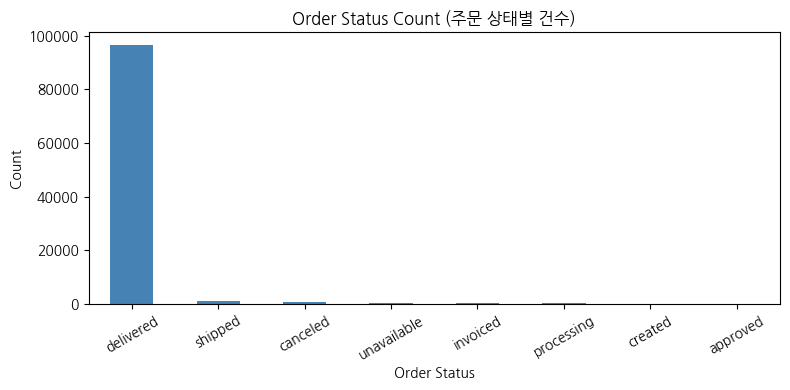

In [7]:
# 셀 6. 주문 상태 분포 확인
# delivered(배송완료)가 가장 많으면 정상입니다.
# orders 사용 : 주문 1건 = 1행 기준으로 셉니다. (df는 같은 주문이 여러 행)

status_count = orders["order_status"].value_counts()
print(status_count)

status_count.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Order Status Count (주문 상태별 건수)")
plt.xlabel("Order Status")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

| 주문 상태 | 의미 | 건수 |
|---|---|---|
| delivered | 배송 완료 | 96,478 |
| shipped | 배송 중 | 1,107 |
| canceled | 취소 | 625 |
| unavailable | 상품 없음 | 609 |

> delivered가 압도적으로 많다 → 대부분 주문이 정상 배송되었습니다.

In [8]:
# 셀 7. 월별 총 결제 금액 분석
# dt.to_period("M"): 날짜를 "2017-10" 형태의 연-월로 변환
# groupby로 같은 월끼리 묶고 payment_value를 합산합니다.
# pay 사용 : 결제 1건 = 1행 기준으로 더해야 중복 없이 계산됩니다.

monthly_sales = pay.groupby(
    pay["order_purchase_timestamp"].dt.to_period("M")
)["payment_value"].sum()

# 주문이 한 건도 없는 달(2016-11)은 groupby 결과에서 아예 빠집니다.
# 빠진 달을 0으로 채워야 그래프가 거짓으로 이어지지 않습니다.
all_months = pd.period_range(monthly_sales.index.min(), monthly_sales.index.max(), freq="M")
monthly_sales = monthly_sales.reindex(all_months, fill_value=0)

print(monthly_sales.round(0))

2016-09        252.0
2016-10      59090.0
2016-11          0.0
2016-12         20.0
2017-01     138488.0
2017-02     291908.0
2017-03     449864.0
2017-04     417788.0
2017-05     592919.0
2017-06     511276.0
2017-07     592383.0
2017-08     674396.0
2017-09     727762.0
2017-10     779678.0
2017-11    1194883.0
2017-12     878401.0
2018-01    1115004.0
2018-02     992463.0
2018-03    1159652.0
2018-04    1160785.0
2018-05    1153982.0
2018-06    1023880.0
2018-07    1066541.0
2018-08    1022425.0
2018-09       4440.0
2018-10        590.0
Freq: M, Name: payment_value, dtype: float64


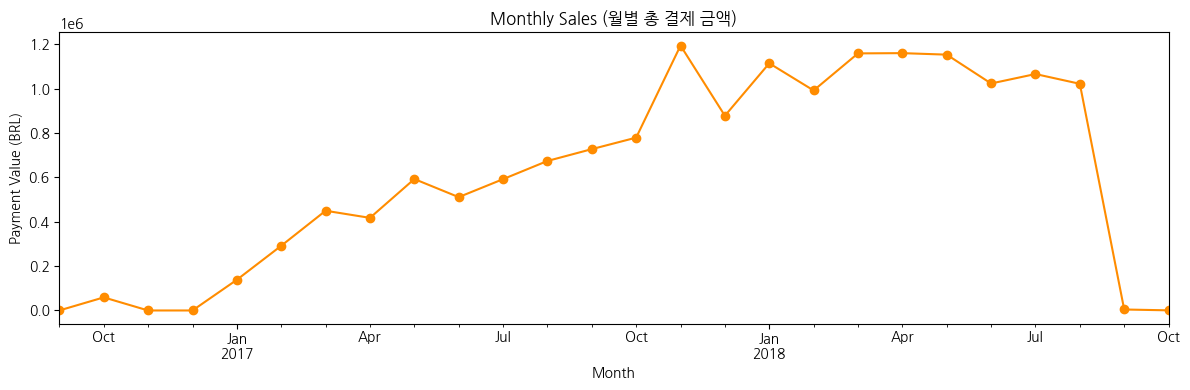

In [9]:
# 셀 8. 월별 총 결제 금액 시각화

monthly_sales.plot(figsize=(12, 4), color="darkorange", marker="o")
plt.title("Monthly Sales (월별 총 결제 금액)")
plt.xlabel("Month")
plt.ylabel("Payment Value (BRL)")
plt.tight_layout()
plt.show()

## 그래프 해석

```
2016-09 ~ 2016-12  → 데이터가 거의 없음 (2016-11은 0건, 2016-12는 1건)
2017년              → 꾸준한 성장, 11월에 크게 튐 (블랙프라이데이 → 인사이트 6)
2018년 1~8월        → 월 100만 BRL 안팎에서 유지
2018-09 이후 급락   → 데이터 수집 종료 영향
```

> **주의:** 마지막 구간이 급락한다고 실제 매출이 감소한 것이 아닙니다.
> 데이터 수집이 그 시점에 끊겼기 때문입니다.
> 아래 셀에서 주문 건수도 함께 확인하면 원인을 알 수 있습니다.

In [10]:
# 셀 9. 월별 주문 건수 확인 (매출 급락 원인 분석)
# 주문 건수도 같이 줄어들면 → 데이터 수집 종료가 원인
# orders 사용 : 주문 1건 = 1행이므로 size()로 세면 주문 수가 됩니다.

monthly_orders = orders.groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
).size()

print(monthly_orders)
# ▶ 2018-09, 2018-10은 주문이 16건, 4건뿐입니다. → 데이터 부족이 원인입니다.

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


---
## 📅 분석 기간 정하기 — 인사이트를 계산할 기준 데이터

위 결과를 보면 데이터 **앞뒤 끝부분은 비어 있거나 불완전**합니다.
이런 구간을 섞으면 "매출이 급락했다" 같은 **틀린 결론**이 나옵니다.

| 기준 | 값 | 이유 |
|---|---|---|
| 시작일 | 2017-01-05 | 2016-12-23 ~ 2017-01-04 사이 주문이 **0건**. 이날부터 주문이 다시 이어집니다. |
| 종료일 | 2018-08-29 | 배송 완료된 주문 중 **가장 마지막 주문일** |
| 주문 상태 | delivered | 취소·배송 중 주문은 매출·배송 기간·리뷰를 왜곡합니다. |
| 배송일 | 값이 있는 주문만 | 배송 기간을 계산하려면 도착일이 있어야 합니다. |

> 이 기준으로 만든 데이터를 `base`라고 부르고, **인사이트 1~10은 모두 `base`로 계산**합니다.


In [11]:
# 셀 9-1. 분석용 기준 데이터(base) 만들기

start_date = "2017-01-05"
end_date   = "2018-08-30"   # "< 2018-08-30" → 2018-08-29 23:59:59까지 포함

base = orders[
    (orders["order_status"] == "delivered")                 # 배송 완료 주문만
    & (orders["order_delivered_customer_date"].notna())     # 도착일이 있는 주문만
    & (orders["order_purchase_timestamp"] >= start_date)
    & (orders["order_purchase_timestamp"] <  end_date)
].copy()

# 주문별 결제 총액 : 결제를 나눠 낸 주문도 있으므로 pay에서 주문별로 합칩니다.
# map() : order_id를 기준으로 합계 값을 찾아 연결
base["order_value"] = base["order_id"].map(
    pay.groupby("order_id")["payment_value"].sum()
)

# 배송 기간(일) = 도착 시각 - 주문 시각
base["delivery_days"] = (
    base["order_delivered_customer_date"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 86400   # 초 → 일(하루 = 86,400초)

# 지연 여부 = 실제 도착이 안내된 도착 예정일보다 늦었는가
base["is_late"] = base["order_delivered_customer_date"] > base["order_estimated_delivery_date"]

print(f"기준 데이터(base) 주문 수 : {len(base):,}건")
print(f"매출 합계                 : R$ {base['order_value'].sum():,.0f}")
print(f"객단가(주문 1건 평균)     : R$ {base['order_value'].mean():,.1f}")
print(f"배송 기간(중앙값)         : {base['delivery_days'].median():.1f}일")
print(f"배송 지연율               : {base['is_late'].mean():.1%}")
print(f"평균 리뷰 점수            : {base['review_score'].mean():.2f}점")

기준 데이터(base) 주문 수 : 96,203건
매출 합계                 : R$ 15,374,497
객단가(주문 1건 평균)     : R$ 159.8
배송 기간(중앙값)         : 10.2일
배송 지연율               : 8.1%
평균 리뷰 점수            : 4.16점


product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64


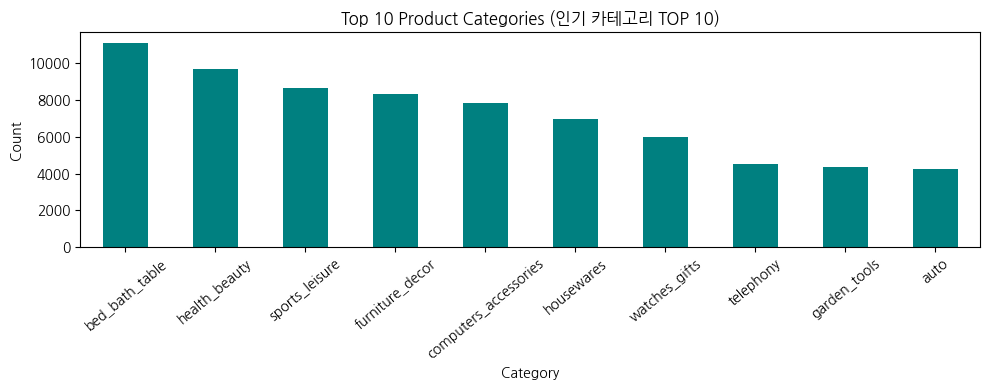

In [12]:
# 셀 10. 인기 상품 카테고리 TOP 10
# items 사용 : 판매된 상품 1개 = 1행 기준으로 셉니다.

top_categories = items["product_category_name_english"].value_counts().head(10)
print(top_categories)

top_categories.plot(kind="bar", figsize=(10, 4), color="teal")
plt.title("Top 10 Product Categories (인기 카테고리 TOP 10)")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

review_score
1.0    11353
2.0     3133
3.0     8124
4.0    19044
5.0    57019
Name: count, dtype: int64


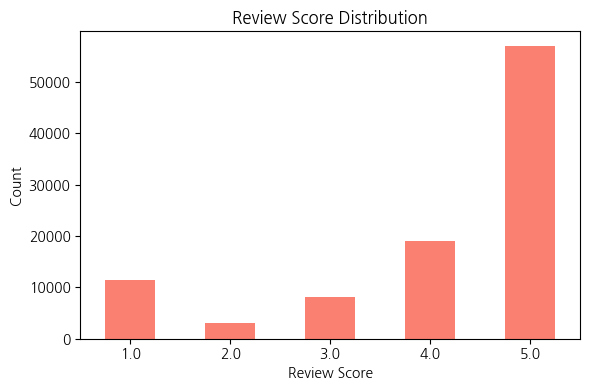

In [13]:
# 셀 11. 리뷰 점수 분포 확인
# 5점이 가장 많으면 고객 만족도가 높다는 의미입니다.
# orders 사용 : 주문 1건당 리뷰 1개 기준으로 셉니다.

review_dist = orders["review_score"].value_counts().sort_index()
print(review_dist)

review_dist.plot(kind="bar", figsize=(6, 4), color="salmon")
plt.title("Review Score Distribution") # 리뷰 점수 분포
plt.xlabel("Review Score")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# 셀 12. 행 수 vs 주문 수 차이 이해

print(f"전체 행 수:   {len(df):,}")
print(f"고유 주문 수: {df['order_id'].nunique():,}")
print()
print("행 수 > 주문 수인 이유:")
print("  주문 1건에 상품·결제·리뷰가 여러 개이면 그 수만큼 곱해져 행이 늘어납니다.")
print("  예) 상품 2개 × 결제 2건 → 같은 주문이 4행")

전체 행 수:   119,143
고유 주문 수: 99,441

행 수 > 주문 수인 이유:
  주문 1건에 상품·결제·리뷰가 여러 개이면 그 수만큼 곱해져 행이 늘어납니다.
  예) 상품 2개 × 결제 2건 → 같은 주문이 4행


---
# 📊 주요 인사이트 10가지

지금부터는 그래프를 보는 데서 한 걸음 더 나아가 **"그래서 무엇을 알게 되었는가?"**를 숫자로 확인합니다.

| 원칙 | 설명 |
|---|---|
| 기준 데이터 | 모든 인사이트는 `base`(배송 완료 · 2017-01-05 ~ 2018-08-29 · 96,203건)로 계산합니다. |
| 집계 단위 | 주문은 `base`/`orders`, 상품은 `items`, 결제는 `pay`를 사용합니다. |
| 해석 | 숫자 → 의미 → 비즈니스 시사점 순서로 정리합니다. |

| 번호 | 인사이트 |
|---|---|
| 1 | 고객 대부분이 한 번 사고 떠난다 |
| 2 | 고객은 남동부 3개 주에 몰려 있다 |
| 3 | 신용카드 할부가 구매의 기본이다 |
| 4 | '보통 주문'은 평균보다 훨씬 작다 |
| 5 | 성장은 객단가가 아니라 주문 수에서 왔다 |
| 6 | 블랙프라이데이 — 그리고 공정한 비교의 중요성 |
| 7 | 평일 낮에 사고, 새벽·주말에는 덜 산다 |
| 8 | 많이 팔리는 것과 돈이 되는 것은 다르다 |
| 9 | 배송이 늦으면 리뷰가 무너진다 |
| 10 | 성수기와 먼 지역에서 배송이 늦어진다 |

## 인사이트 1. 고객 대부분이 한 번 사고 떠난다

> 질문: 한 사람이 평균 몇 번 주문할까?
> 📌 `customer_id`는 주문할 때마다 새로 발급됩니다. **실제 한 사람은 `customer_unique_id`**로 세야 합니다.

In [15]:
# 인사이트 1. 고객별 주문 횟수
# customer_unique_id : 실제 한 사람을 구분하는 번호

orders_per_customer = base.groupby("customer_unique_id")["order_id"].nunique()

one_time_rate = (orders_per_customer == 1).mean()   # True(1)의 평균 = 비율

print(f"고객 수              : {len(orders_per_customer):,}명")
print(f"1번만 구매한 고객    : {one_time_rate:.1%}")
print(f"2번 이상 구매한 고객 : {1 - one_time_rate:.1%}")
print()
print("주문 횟수별 고객 수")
print(orders_per_customer.value_counts().sort_index().head(5))

고객 수              : 93,096명
1번만 구매한 고객    : 97.0%
2번 이상 구매한 고객 : 3.0%

주문 횟수별 고객 수
order_id
1    90307
2     2562
3      180
4       28
5        9
Name: count, dtype: int64


**해석**
- 고객 **97.0%가 딱 한 번만** 구매했고, 재구매 고객은 **3.0%**에 불과합니다.
- Olist는 "단골이 반복해서 사는 쇼핑몰"이 아니라 **"새 고객이 계속 들어와야 유지되는 구조"**입니다.

**비즈니스 시사점**
- 신규 고객 획득 비용이 매출을 좌우합니다. 두 번째 구매를 유도하는 장치(재구매 쿠폰, 리마인드)가 가장 큰 기회입니다.
- 🔗 그래서 이 데이터로는 '고객 이탈(재구매) 예측' 모델을 만들기 어렵습니다. 재구매하는 사람이 거의 없어 "돌아올 고객"의 패턴을 배울 예가 너무 적기 때문입니다. 이 과정에서 고객 대신 **상품(PART 6)**, **리뷰(PART 7-1~7-3)**, **판매자(PART 8·9)**를 분석하는 이유입니다.

## 인사이트 2. 고객은 남동부 3개 주에 몰려 있다

> 질문: 주문은 브라질 어디에서 들어올까?
> 📌 브라질은 27개 주(州)로 나뉩니다. SP(상파울루) · RJ(리우데자네이루) · MG(미나스제라이스)는 모두 **남동부**에 있습니다.

주문 비중 TOP 5
customer_state
SP    42.0%
RJ    12.8%
MG    11.8%
RS     5.5%
PR     5.1%
Name: proportion, dtype: object

SP + RJ + MG 주문 비중 : 66.6%
SP + RJ + MG 매출 비중 : 62.5%


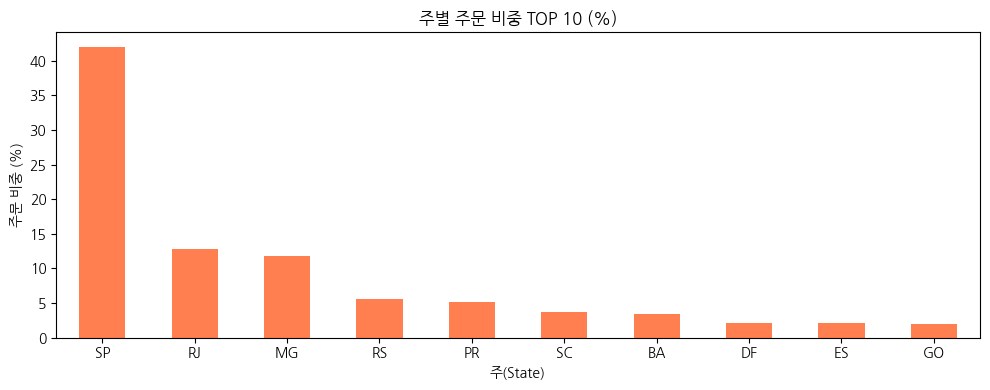

In [16]:
# 인사이트 2. 주(state)별 주문 비중
# value_counts(normalize=True) : 개수 대신 비율(0~1)로 계산

state_share = base["customer_state"].value_counts(normalize=True)

print("주문 비중 TOP 5")
print((state_share.head(5) * 100).round(1).astype(str) + "%")
print()
print(f"SP + RJ + MG 주문 비중 : {state_share.head(3).sum():.1%}")

# 매출 기준으로도 확인 (주문 수와 매출은 다를 수 있으므로)
state_sales_share = base.groupby("customer_state")["order_value"].sum() / base["order_value"].sum()
print(f"SP + RJ + MG 매출 비중 : {state_sales_share[['SP', 'RJ', 'MG']].sum():.1%}")

(state_share.head(10) * 100).plot(kind="bar", figsize=(10, 4), color="coral")
plt.title("주별 주문 비중 TOP 10 (%)")
plt.xlabel("주(State)")
plt.ylabel("주문 비중 (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**해석**
- SP 42.0%, RJ 12.8%, MG 11.8% → **3개 주가 주문의 66.6%**를 차지합니다. 매출 기준으로도 62.5%입니다.
- 나머지 24개 주를 모두 합쳐도 3분의 1이 안 됩니다.

**비즈니스 시사점**
- 물류센터·마케팅 예산은 남동부에 집중하는 것이 효율적입니다.
- 반대로 다른 지역은 아직 성장 여지가 큰 시장입니다. 다만 배송이 걸림돌입니다. (→ 인사이트 10)

## 인사이트 3. 신용카드 할부가 구매의 기본이다

> 질문: 고객은 어떻게 결제할까?
> 📌 `boleto`(볼레토)는 브라질의 **은행 납부 전표**입니다. 전표를 받아 은행·편의점에서 현금으로 냅니다.
> 📌 한 주문을 여러 수단으로 나눠 낼 수 있으므로, 주문마다 **가장 큰 금액을 낸 수단**을 그 주문의 주 결제수단으로 봅니다.

In [17]:
# 인사이트 3. 결제 수단과 할부

# base에 포함된 주문의 결제만 사용 (pay : 결제 1건 = 1행)
base_pay = pay[pay["order_id"].isin(base["order_id"])]

# idxmax() : 주문별로 결제 금액이 가장 큰 행의 위치를 찾습니다.
main_pay = base_pay.loc[base_pay.groupby("order_id")["payment_value"].idxmax()]

print("주문별 주 결제수단 비율")
print((main_pay["payment_type"].value_counts(normalize=True) * 100).round(1).astype(str) + "%")
print()

# 신용카드 결제의 할부 개월 수 (1 = 일시불)
card = base_pay[base_pay["payment_type"] == "credit_card"]
print(f"신용카드 결제 중 할부(2개월 이상) : {(card['payment_installments'] > 1).mean():.1%}")
print(f"평균 할부 개월 수                 : {card['payment_installments'].mean():.1f}개월")
print(f"할부 개월 수 중앙값               : {card['payment_installments'].median():.0f}개월")

주문별 주 결제수단 비율
payment_type
credit_card    75.5%
boleto         19.9%
voucher         3.1%
debit_card      1.5%
Name: proportion, dtype: object

신용카드 결제 중 할부(2개월 이상) : 66.8%
평균 할부 개월 수                 : 3.5개월
할부 개월 수 중앙값               : 3개월


**해석**
- 주문의 **75.5%가 신용카드**, 19.9%가 볼레토로 결제됩니다.
- 신용카드 결제의 **3건 중 2건(66.8%)이 할부**이고, 평균 3.5개월로 나눠 냅니다.
- 객단가가 R$160 정도로 크지 않은데도 할부를 쓴다는 점이 특징입니다. 브라질에서는 소액도 무이자 할부(parcelado)로 사는 문화가 일반적입니다.

**비즈니스 시사점**
- "무이자 N개월"은 할인과 같은 효과를 내는 핵심 판매 조건입니다.
- 카드가 없는 고객(볼레토 약 20%)을 위한 결제 수단도 유지해야 합니다.

## 인사이트 4. '보통 주문'은 평균보다 훨씬 작다

> 질문: 평균 객단가 R$160이 '보통 고객'의 주문 금액일까?
> 📌 **평균(mean)**은 큰 값 몇 개에 끌려 올라갑니다. **중앙값(median)**은 한가운데 값이라 '보통'을 더 잘 나타냅니다.

평균 주문 금액   : R$ 159.8
중앙값 주문 금액 : R$ 105.3
평균보다 작은 주문 비율 : 70.4%


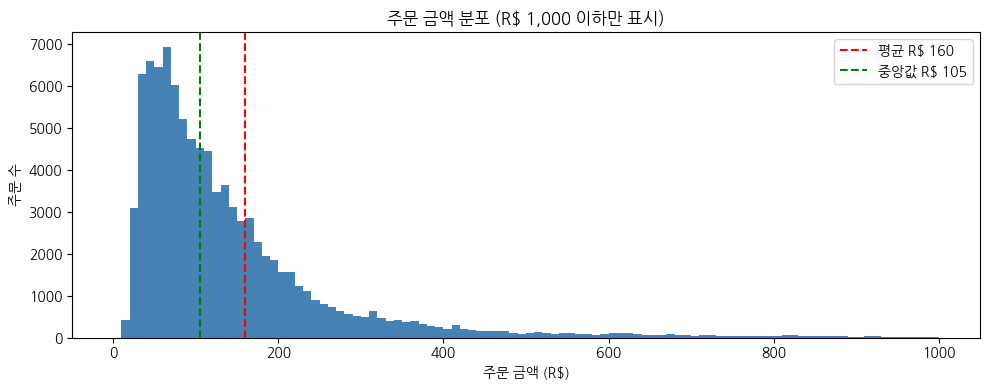

In [18]:
# 인사이트 4. 주문 금액 분포 : 평균 vs 중앙값

mean_value   = base["order_value"].mean()
median_value = base["order_value"].median()

print(f"평균 주문 금액   : R$ {mean_value:,.1f}")
print(f"중앙값 주문 금액 : R$ {median_value:,.1f}")
print(f"평균보다 작은 주문 비율 : {(base['order_value'] < mean_value).mean():.1%}")

plt.figure(figsize=(10, 4))
plt.hist(base["order_value"], bins=100, range=(0, 1000), color="steelblue")
plt.axvline(mean_value,   color="red",   linestyle="--", label=f"평균 R$ {mean_value:.0f}")
plt.axvline(median_value, color="green", linestyle="--", label=f"중앙값 R$ {median_value:.0f}")
plt.title("주문 금액 분포 (R$ 1,000 이하만 표시)")
plt.xlabel("주문 금액 (R$)")
plt.ylabel("주문 수")
plt.legend()
plt.tight_layout()
plt.show()

**해석**
- 평균은 R$159.8이지만 중앙값은 **R$105.3**입니다.
- 주문의 **70.4%가 평균보다 작습니다.** 소수의 고가 주문이 평균을 끌어올린 것입니다.
- 분포가 오른쪽으로 길게 늘어진 모양(right-skewed)일 때 평균만 보면 '보통 고객'을 잘못 이해하게 됩니다.

**비즈니스 시사점**
- 프로모션 기준(예: "R$150 이상 무료배송")을 정할 때는 평균이 아니라 **중앙값과 분포**를 봐야 합니다.

## 인사이트 5. 성장은 객단가가 아니라 주문 수에서 왔다

> 질문: 매출이 늘어난 이유는 '더 많이 주문해서'일까, '한 번에 더 비싸게 사서'일까?
> 📌 **매출 = 주문 수 × 객단가**입니다. 둘 중 무엇이 변했는지 나눠 보면 원인을 알 수 있습니다.
> 📌 2018년 데이터는 8월까지만 있으므로 **두 해 모두 1~8월**만 비교해야 공정합니다.

                            주문수         매출    객단가
order_purchase_timestamp                         
2017                      21997  3473668.8  157.9
2018                      52777  8451925.1  160.1

주문 수 증가 : 2.40배
매출 증가    : 2.43배
객단가 변화  : +1.4%


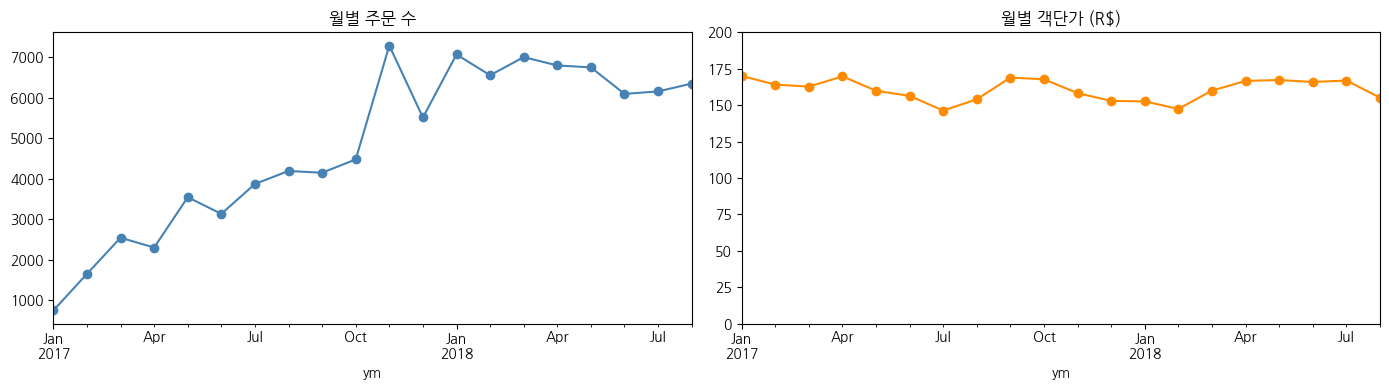

In [19]:
# 인사이트 5. 매출 = 주문 수 × 객단가 분해 (같은 기간 1~8월 비교)

base["ym"] = base["order_purchase_timestamp"].dt.to_period("M")
jan_aug = base[base["order_purchase_timestamp"].dt.month <= 8]

compare = jan_aug.groupby(jan_aug["order_purchase_timestamp"].dt.year).agg(
    주문수=("order_id", "count"),
    매출=("order_value", "sum"),
    객단가=("order_value", "mean"),
)
print(compare.round(1))
print()
print(f"주문 수 증가 : {compare.loc[2018, '주문수'] / compare.loc[2017, '주문수']:.2f}배")
print(f"매출 증가    : {compare.loc[2018, '매출']   / compare.loc[2017, '매출']:.2f}배")
print(f"객단가 변화  : {compare.loc[2018, '객단가'] / compare.loc[2017, '객단가'] - 1:+.1%}")

# 월별 추이 : 주문 수는 크게 늘지만 객단가는 거의 평평합니다.
monthly = base.groupby("ym").agg(주문수=("order_id", "count"), 객단가=("order_value", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly["주문수"].plot(ax=axes[0], marker="o", color="steelblue", title="월별 주문 수")
monthly["객단가"].plot(ax=axes[1], marker="o", color="darkorange", title="월별 객단가 (R$)")
axes[1].set_ylim(0, 200)   # 0부터 그려야 변화 크기를 정직하게 볼 수 있습니다.
plt.tight_layout()
plt.show()

**해석**
- 1~8월 기준 2017년 → 2018년, 주문 수는 21,997건 → 52,777건으로 **2.40배** 늘었습니다.
- 같은 기간 객단가는 R$157.9 → R$160.1로 **+1.4%**, 사실상 그대로입니다.
- 매출 성장(2.43배)은 거의 전부 **주문 수(고객 수) 증가**에서 나왔습니다.

**비즈니스 시사점**
- 지금까지의 성장 엔진은 "더 많은 신규 고객"입니다. 인사이트 1(재구매 3%)과 합치면 성장이 **신규 유입에 크게 의존**한다는 뜻입니다.
- 다음 성장 레버는 객단가(묶음 판매, 추천) 또는 재구매입니다. (이 데이터로 고객 기반 추천 대신 상품 기반 추천(PART 6)을 하는 이유는 PART 10에서 확인합니다)

## 인사이트 6. 블랙프라이데이 — 그리고 공정한 비교의 중요성

> 질문: 2017년 11월 매출은 왜 튀었을까? 그리고 12월은 정말 '감소'한 걸까?
> 📌 블랙프라이데이: 미국 추수감사절 다음 금요일의 대규모 할인 행사. 브라질에서도 큰 쇼핑 이벤트입니다. (2017년은 11월 24일)

주문이 가장 많았던 날 TOP 5
order_purchase_timestamp
2017-11-24    1147
2017-11-25     487
2017-11-27     395
2017-11-26     382
2017-11-28     371
dtype: int64

하루 주문 수 중앙값 : 148건
2017-11-24 주문 수  : 1,147건 → 평소의 7.8배

2017년 10~12월 월별 주문 수
ym
2017-10    4478
2017-11    7288
2017-12    5513
Freq: M, Name: 주문수, dtype: int64


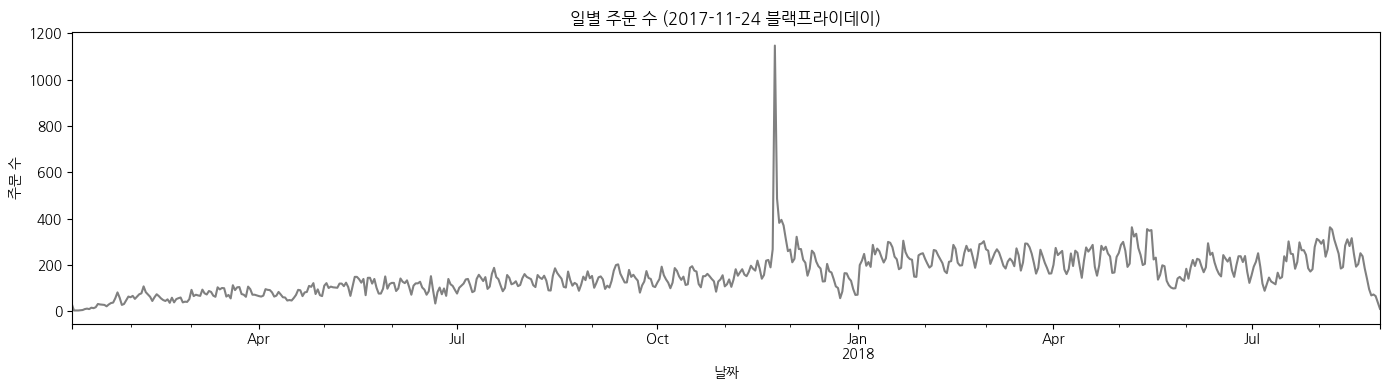

In [20]:
# 인사이트 6. 일별 주문 수와 블랙프라이데이

daily_orders = base.groupby(base["order_purchase_timestamp"].dt.date).size()
daily_orders.index = pd.to_datetime(daily_orders.index)   # 날짜 형식으로 맞춰야 그래프가 안정적으로 그려집니다

print("주문이 가장 많았던 날 TOP 5")
print(daily_orders.sort_values(ascending=False).head(5))
print()
print(f"하루 주문 수 중앙값 : {daily_orders.median():.0f}건")
print(f"2017-11-24 주문 수  : {daily_orders.max():,}건 → 평소의 {daily_orders.max() / daily_orders.median():.1f}배")
print()
print("2017년 10~12월 월별 주문 수")
print(monthly.loc["2017-10":"2017-12", "주문수"])

daily_orders.plot(figsize=(14, 4), color="gray")
plt.title("일별 주문 수 (2017-11-24 블랙프라이데이)")
plt.xlabel("날짜")
plt.ylabel("주문 수")
plt.tight_layout()
plt.show()

**해석**
- 2017-11-24 하루에만 **1,147건**이 들어왔습니다. 평소 하루 중앙값(148건)의 **7.8배**입니다. 이후 4일(11/25~28)도 평소의 2.5~3.3배입니다.
- 그래서 11월(7,288건)이 튀고, 12월(5,513건)은 "11월보다 24% 감소"처럼 보입니다. 하지만 12월은 10월(4,478건)보다 오히려 많습니다.

**공정한 비교의 원칙**
| 잘못된 비교 | 공정한 비교 |
|---|---|
| 12월 vs 블랙프라이데이가 있는 11월 → "감소" | 행사 효과를 빼고 보거나, 전년 같은 달과 비교 |
| 2017년 전체 vs 2018년(8월까지) → "2018년 매출이 적다" | **같은 기간(1~8월)**끼리 비교 (인사이트 5) |
| 데이터 끝 2018-09 → "매출 급락" | 수집이 끝난 구간은 제외 (분석 기간 설정) |

**비즈니스 시사점**
- 블랙프라이데이는 1년 중 가장 큰 단일 이벤트입니다. 재고·물류·CS 인력을 미리 준비해야 합니다.
- 성과를 평가할 때는 항상 **"무엇과 비교했는가"**를 먼저 확인해야 합니다.

## 인사이트 7. 평일 낮에 사고, 새벽·주말에는 덜 산다

> 질문: 고객은 언제 주문할까?
> 📌 dayofweek: 0=월 … 6=일 / hour: 0~23시

요일별 주문 비중
월    16.3%
화    16.1%
수    15.6%
목    14.8%
금    14.2%
토    10.9%
일    12.1%
Name: proportion, dtype: object

낮 10~16시 주문 비중   : 45.2%
저녁 17~22시 주문 비중 : 36.3%
새벽 0~5시 주문 비중   : 4.8%

요일별 저녁 18~22시 주문 수
월    4847
화    4611
수    4294
목    4023
금    3535
토    3298
일    4410
Name: count, dtype: int64


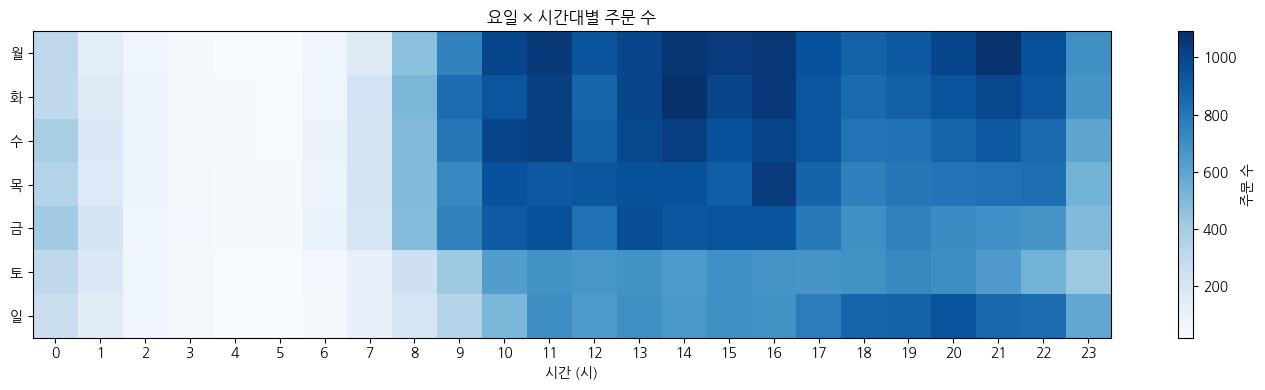

In [21]:
# 인사이트 7. 요일 × 시간대별 주문 수

day_names = ["월", "화", "수", "목", "금", "토", "일"]

# 요일별 주문 비중
dow_share = base["dayofweek"].value_counts(normalize=True).sort_index()
dow_share.index = day_names
print("요일별 주문 비중")
print((dow_share * 100).round(1).astype(str) + "%")
print()

# 시간대별 주문 비중
hour_share = base["hour"].value_counts(normalize=True).sort_index()
print(f"낮 10~16시 주문 비중   : {hour_share.loc[10:16].sum():.1%}")
print(f"저녁 17~22시 주문 비중 : {hour_share.loc[17:22].sum():.1%}")
print(f"새벽 0~5시 주문 비중   : {hour_share.loc[0:5].sum():.1%}")
print()

# 저녁 18~22시만 따로 보면? (히트맵에서 일요일 저녁이 진하게 보이는 이유 확인)
evening = base[base["hour"].between(18, 22)]
evening_by_day = evening["dayofweek"].value_counts().sort_index()
evening_by_day.index = day_names
print("요일별 저녁 18~22시 주문 수")
print(evening_by_day)

# pivot_table : 행=요일, 열=시간, 값=주문 수 → 히트맵으로 표시
heat = base.pivot_table(index="dayofweek", columns="hour", values="order_id", aggfunc="count")
heat.index = day_names

plt.figure(figsize=(14, 4))
plt.imshow(heat, aspect="auto", cmap="Blues")
plt.colorbar(label="주문 수")
plt.yticks(range(7), day_names)
plt.xticks(range(24))
plt.title("요일 × 시간대별 주문 수")
plt.xlabel("시간 (시)")
plt.tight_layout()
plt.show()

**해석**
- 월요일(16.3%)이 가장 많고 **토요일(10.9%)·일요일(12.1%)이 가장 적습니다.** 주말에 덜 삽니다.
- 시간대는 **낮 10~16시가 45.2%**로 가장 많고, 저녁 17~22시도 높게 이어집니다.
- **새벽 0~5시는 4.8%**에 불과합니다.
- ⚠️ 예외: **일요일 저녁(18~22시)**은 4,410건으로 목요일(4,023건)·금요일(3,535건)의 같은 시간대보다 많습니다. 주말 중 덜 사는 건 **토요일**이고, 일요일은 낮에 적다가 저녁에 다시 늘어납니다.

**비즈니스 시사점**
- 일과 중 틈틈이 주문하는 패턴으로 **추정**할 수 있습니다. (이유는 데이터로 확인한 것이 아니라 해석입니다.)
- 광고·푸시 알림은 평일 오전~저녁에 집중합니다.
- 서버 점검이나 배포는 주문이 가장 적은 새벽 3~5시가 안전합니다.

## 인사이트 8. 많이 팔리는 것과 돈이 되는 것은 다르다

> 질문: 판매 개수 1위 카테고리가 매출도 1위일까?
> 📌 `items` 사용 : 상품 1개 = 1행. 매출은 상품 가격(price) 합계로 계산합니다. (배송비 제외)

In [22]:
# 인사이트 8. 카테고리별 판매 개수 순위 vs 매출 순위

base_items = items[items["order_id"].isin(base["order_id"])]

category = base_items.groupby("product_category_name_english").agg(
    판매개수=("order_item_id", "count"),
    매출=("price", "sum"),
)
category["개수순위"] = category["판매개수"].rank(ascending=False).astype(int)
category["매출순위"] = category["매출"].rank(ascending=False).astype(int)
category["평균가격"] = (category["매출"] / category["판매개수"]).round(1)

print("판매 개수 TOP 10과 매출 순위 비교")
print(category.sort_values("판매개수", ascending=False).head(10)[["판매개수", "개수순위", "매출순위", "평균가격"]])
print()

# 매출 상위 몇 개 카테고리가 전체 매출의 80%를 만들까? (파레토 분석)
# cumsum() : 위에서부터 차례로 더한 누적 합계
sales_sorted = category["매출"].sort_values(ascending=False)
cum_share = sales_sorted.cumsum() / sales_sorted.sum()
n_80 = (cum_share < 0.8).sum() + 1          # 누적 비율이 80%를 처음 넘는 순위
print(f"전체 카테고리 수               : {len(sales_sorted)}개")
print(f"매출 80%를 만드는 상위 카테고리 : {n_80}개 (누적 {cum_share.iloc[n_80 - 1]:.1%})")
print(f"→ 전체의 {n_80 / len(sales_sorted):.0%} 카테고리가 매출의 80%를 차지")

판매 개수 TOP 10과 매출 순위 비교
                                판매개수  개수순위  매출순위   평균가격
product_category_name_english                          
bed_bath_table                 10945     1     3   93.5
health_beauty                   9422     2     1  130.5
sports_leisure                  8413     3     4  113.2
furniture_decor                 8095     4     6   87.2
computers_accessories           7631     5     5  116.4
housewares                      6783     6     7   90.6
watches_gifts                   5853     7     2  198.7
telephony                       4422     8    14   70.0
garden_tools                    4263     9    10  110.0
auto                            4131    10     9  139.9

전체 카테고리 수               : 71개
매출 80%를 만드는 상위 카테고리 : 17개 (누적 80.8%)
→ 전체의 24% 카테고리가 매출의 80%를 차지


**해석**
| 카테고리 | 판매 개수 순위 | 매출 순위 | 이유 |
|---|---|---|---|
| bed_bath_table (침구·욕실) | **1위** | 3위 | 싸고 많이 팔림 |
| health_beauty (건강·미용) | 2위 | **1위** | 많이 팔리고 가격도 중간 이상 |
| watches_gifts (시계·선물) | 7위 | **2위** | 개당 가격이 높음 (평균 약 R$199) |
| telephony (전화기·액세서리) | 8위 | **14위** | 저가 액세서리 위주 (평균 약 R$70) |

- "인기 카테고리 TOP 10"(개수 기준)만 보면 **watches_gifts의 가치를 놓치게 됩니다.**
- 매출은 소수 카테고리에 몰려 있습니다. 71개 카테고리 중 **상위 17개(약 24%)가 매출의 80.8%**를 만듭니다. (파레토 법칙: 소수가 대부분을 만든다)
- 📌 카테고리가 없는(미분류) 상품까지 한 그룹으로 세면 18개가 필요합니다. 기준에 따라 숫자가 달라질 수 있으니 **무엇을 셌는지 함께 적어야** 합니다.

**비즈니스 시사점**
- 매출 상위 17개 카테고리는 재고·광고를 집중 관리하고, 나머지는 효율 위주로 운영합니다.
- 목표에 따라 기준을 고릅니다. 트래픽·신규 유입은 **판매 개수**, 수익은 **매출(또는 이익)** 기준입니다.
- 광고비는 매출 순위가 높은 카테고리에, 묶음 판매는 판매 개수가 많은 저가 카테고리에 효과적입니다.

## 인사이트 9. 배송이 늦으면 리뷰가 무너진다

> 질문: 배송 지연은 고객 만족(리뷰 점수)에 얼마나 영향을 줄까?
> 📌 지연 = 실제 도착 시각이 **안내된 도착 예정일보다 늦은** 경우

         리뷰수   평균리뷰  별1개비율
제때 도착  87902  4.295  0.066
지연 도착   7658  2.566  0.462

배송 지연율 : 8.1%
지연 주문 리뷰 중 '상품 도착 전'에 작성된 비율 : 62.2%
  도착 전에 작성된 리뷰 평균 : 1.84점
  도착 후에 작성된 리뷰 평균 : 3.75점



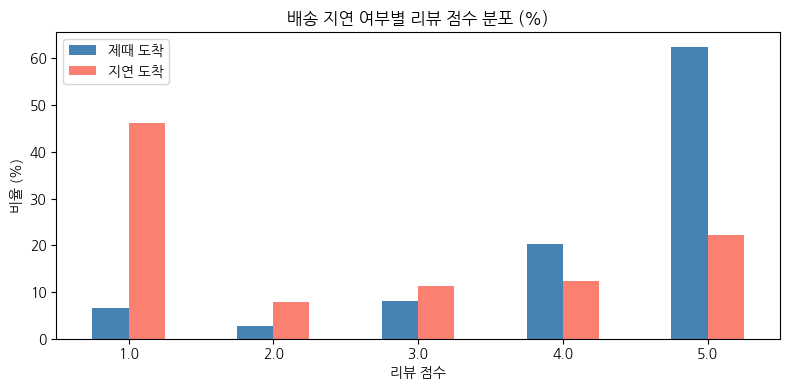

In [23]:
# 인사이트 9. 배송 지연 여부별 리뷰 점수

# 리뷰가 없는 주문은 빼고 계산합니다. (분모를 '리뷰를 남긴 주문'으로 맞추기)
reviewed = base.dropna(subset=["review_score"])

review_by_late = reviewed.groupby("is_late").agg(
    리뷰수=("order_id", "count"),
    평균리뷰=("review_score", "mean"),
    별1개비율=("review_score", lambda s: (s == 1).mean()),   # 1점 리뷰 비율
)
review_by_late.index = ["제때 도착", "지연 도착"]
print(review_by_late.round(3))
print()
print(f"배송 지연율 : {base['is_late'].mean():.1%}")

# 지연 여부별 리뷰 점수 분포 비교
dist = pd.crosstab(reviewed["is_late"], reviewed["review_score"], normalize="index") * 100
dist.index = ["제때 도착", "지연 도착"]
# 지연 주문의 리뷰는 '언제' 작성됐을까?
# Olist는 상품이 도착하거나, 도착 예정일이 지나면 만족도 설문을 보냅니다.
late_reviewed  = reviewed[reviewed["is_late"]]
before_arrival = late_reviewed["review_creation_date"] < late_reviewed["order_delivered_customer_date"].dt.normalize()
print(f"지연 주문 리뷰 중 '상품 도착 전'에 작성된 비율 : {before_arrival.mean():.1%}")
print(f"  도착 전에 작성된 리뷰 평균 : {late_reviewed.loc[before_arrival, 'review_score'].mean():.2f}점")
print(f"  도착 후에 작성된 리뷰 평균 : {late_reviewed.loc[~before_arrival, 'review_score'].mean():.2f}점")
print()

dist.T.plot(kind="bar", figsize=(8, 4), color=["steelblue", "salmon"])
plt.title("배송 지연 여부별 리뷰 점수 분포 (%)")
plt.xlabel("리뷰 점수")
plt.ylabel("비율 (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**해석**
- 제때 도착하면 평균 **4.30점**, 늦게 도착하면 **2.57점**입니다.
- 1점 리뷰 비율은 6.6% → **46.2%**로 약 7배가 됩니다. 늦게 받은 고객 거의 절반이 최저점을 줍니다.
- 지연 주문은 전체의 8.1%뿐이지만, **1점 리뷰의 약 38%**가 지연 주문에서 나옵니다.
- 📌 **언제 쓴 리뷰일까?** 지연 주문 리뷰의 **62.2%는 상품이 도착하기 전**에 작성됐습니다(평균 1.84점).
  Olist는 도착 예정일이 지나면 만족도 설문을 보내기 때문에, 고객은 **기다리다 지친 상태**에서 리뷰를 씁니다.
  늦더라도 받은 뒤에 쓴 리뷰는 평균 3.75점으로, 제때 받은 경우(4.30점)보다는 낮지만 훨씬 덜 나쁩니다.
- 즉, 리뷰를 무너뜨리는 것은 '늦음' 그 자체보다 **"예정일이 지났는데 아직 못 받은 상태"**입니다. (리뷰가 있는 지연 주문 7,658건 × 46.2% ≈ 3,537건)

**비즈니스 시사점**
- 리뷰를 올리는 가장 확실한 방법은 상품이 아니라 **약속한 날짜를 지키는 것**입니다.
- 도착 예정일을 너무 빠듯하게 안내하지 않는 것도 방법입니다(기대 관리).
- 예정일이 지난 주문에는 설문보다 **먼저 상황 안내와 사과**를 보내는 것이 효과적입니다.
- 🔗 실제로 부정 리뷰(1~2점)의 약 63%에 배송 관련 단어(entrega 배송, prazo 기한, chegou 도착, recebi 받았다 등)가 들어 있습니다. (긍정 리뷰도 49%가 "빨리 왔다"처럼 배송을 언급합니다.)
- 🔗 PART 8에서는 지연과 낮은 평점이 몰린 판매자 그룹을 찾고, PART 7-1~7-3에서는 리뷰의 긍정/부정을 자동으로 분류합니다.

### 📌 본문 숫자 직접 확인하기 + 지연 정의 주의

위 해석에 나온 숫자(1점 리뷰 중 지연 비율, 부정 리뷰의 배송 단어 비율)를 코드로 확인합니다.

> ⚠️ **지연 정의 주의**: `order_estimated_delivery_date`(도착 예정일)는 **시각이 00:00:00**으로 저장되어 있습니다.
> 그래서 예정일 **당일** 오후에 도착해도 `도착 시각 > 예정일 00:00` 이 되어 **지연으로 계산**됩니다.
> 아래 셀에서 이런 주문이 지연 주문 중 얼마나 되는지 확인합니다. 숫자를 발표할 때는 **"지연을 어떻게 정의했는가"**를 함께 적어야 합니다.

In [24]:
# 인사이트 9-1. 본문 숫자 확인

# ① 1점 리뷰 중 지연 주문 비율
one_star = reviewed[reviewed["review_score"] == 1]
print(f"1점 리뷰 중 지연 주문 비율             : {one_star['is_late'].mean():.1%}")

# ② 지연 정의 확인 : 예정일 '당일'에 도착했는데 지연으로 잡힌 주문
# dt.normalize() : 시각을 00:00:00으로 맞춰 '날짜'만 남깁니다.
same_day = base["order_delivered_customer_date"].dt.normalize() == base["order_estimated_delivery_date"]
late_same_day = base["is_late"] & same_day
print(f"지연 주문 중 '예정일 당일 도착' 비율   : {late_same_day.sum() / base['is_late'].sum():.1%}")
print(f"  → 날짜 기준(다음 날부터 지연)으로 보면 지연율 : {(base['is_late'] & ~same_day).mean():.1%}  (시각 기준 {base['is_late'].mean():.1%})")
print()

# ③ 리뷰 글에 배송 관련 단어가 들어 있는 비율
# str.contains(정규식) : entreg(배송), prazo(기한), cheg(도착), receb(받다)로 시작하는 단어가 있는지 확인
delivery_words = r"entreg|prazo|cheg|receb"
text_reviews = reviewed.dropna(subset=["review_comment_message"])
msg = text_reviews["review_comment_message"].str.lower()
neg = text_reviews["review_score"] <= 2
pos = text_reviews["review_score"] >= 4
print(f"부정 리뷰(1~2점) 중 배송 단어 포함     : {msg[neg].str.contains(delivery_words).mean():.1%}")
print(f"긍정 리뷰(4~5점) 중 배송 단어 포함     : {msg[pos].str.contains(delivery_words).mean():.1%}")
# ▶ 어떤 단어를 '배송 단어'로 볼지에 따라 숫자가 1~2%p 달라질 수 있습니다.

1점 리뷰 중 지연 주문 비율             : 38.0%
지연 주문 중 '예정일 당일 도착' 비율   : 16.5%
  → 날짜 기준(다음 날부터 지연)으로 보면 지연율 : 6.8%  (시각 기준 8.1%)

부정 리뷰(1~2점) 중 배송 단어 포함     : 63.0%
긍정 리뷰(4~5점) 중 배송 단어 포함     : 48.9%


## 인사이트 10. 성수기와 먼 지역에서 배송이 늦어진다

> 질문: 배송 지연은 **언제**, **어디서** 많이 생길까?
> 📌 전체 평균 지연율은 8.1%입니다. 이보다 높은 '때(성수기)'와 '곳(원거리)'을 찾습니다.
> 📌 판매자의 약 60%가 SP(상파울루)에 있고, 판매된 상품의 71%가 SP 판매자에게서 나갑니다. 북부(AM, RR, AP, PA 등)와 북동부(AL, MA, CE, PB 등)는 거리가 멉니다.
> ⚠️ 주문 수가 100건 미만인 주는 숫자가 크게 흔들릴 수 있으니 해석에 주의합니다.

In [25]:
# 인사이트 10-0. 위 문장의 숫자 확인 — 판매자는 어디에 있을까?
# items : 판매된 상품 1개 = 1행 / seller_id 기준 중복 제거 → 판매자 1명 = 1행

base_items = items[items["order_id"].isin(base["order_id"])]
seller_state = base_items.drop_duplicates("seller_id")["seller_state"]

print(f"판매자 수                       : {len(seller_state):,}명")
print(f"SP(상파울루) 판매자 비율        : {(seller_state == 'SP').mean():.1%}")
print(f"SP 판매자가 판 상품 비율        : {(base_items['seller_state'] == 'SP').mean():.1%}")

판매자 수                       : 2,945명
SP(상파울루) 판매자 비율        : 59.5%
SP 판매자가 판 상품 비율        : 71.4%


          주문수   지연율  배송기간_중앙값
ym                           
2017-01   750   3.1      10.7
2017-02  1653   3.2      11.0
2017-03  2546   5.6      10.1
2017-04  2303   7.9      12.7
2017-05  3545   3.6       9.8
2017-06  3135   3.9      10.8
2017-07  3872   3.4      10.2
2017-08  4193   3.3       9.8
2017-09  4150   5.2      10.3
2017-10  4478   5.3      10.3
2017-11  7288  14.3      12.7
2017-12  5513   8.4      13.1
2018-01  7069   6.6      11.8
2018-02  6555  16.0      14.3
2018-03  7003  21.4      13.4
2018-04  6798   5.3       9.3
2018-05  6749   8.2       9.1
2018-06  6096   1.4       8.0
2018-07  6156   4.5       7.5
2018-08  6351  10.4       7.0


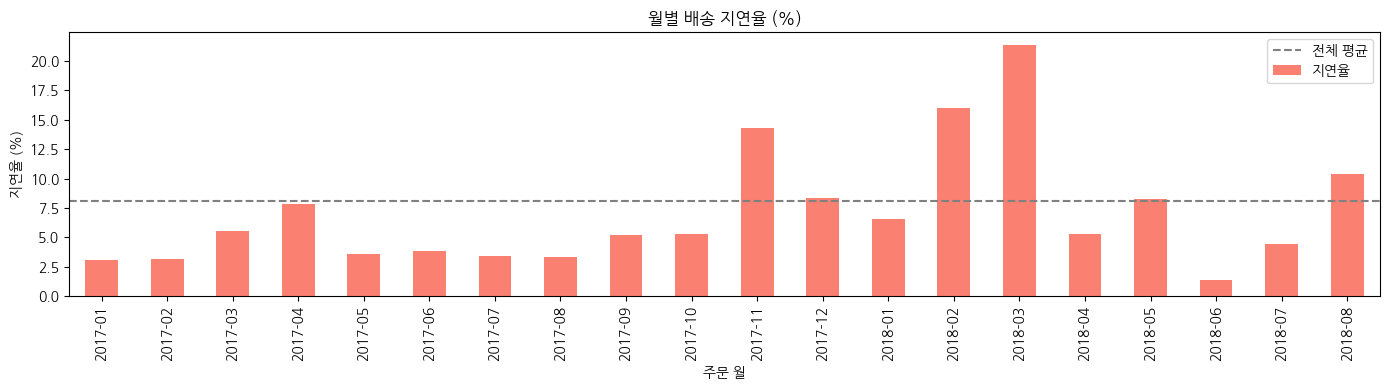

In [26]:
# 인사이트 10-1. 언제? → 월별 지연율 (성수기)

monthly_late = base.groupby("ym").agg(
    주문수=("order_id", "count"),
    지연율=("is_late", "mean"),
    배송기간_중앙값=("delivery_days", "median"),
)
monthly_late["지연율"] = monthly_late["지연율"] * 100   # 비율 → %
print(monthly_late.round(1))

monthly_late["지연율"].plot(kind="bar", figsize=(14, 4), color="salmon")
plt.axhline(base["is_late"].mean() * 100, color="gray", linestyle="--", label="전체 평균")
plt.title("월별 배송 지연율 (%)")
plt.xlabel("주문 월")
plt.ylabel("지연율 (%)")
plt.legend()
plt.tight_layout()
plt.show()

                  주문수  배송기간_중앙값   지연율  평균배송비  평균리뷰
customer_state                                    
SP              40399      7.20  0.06  17.33  4.25
MG              11319     10.31  0.06  23.48  4.19
PR               4903     10.42  0.05  23.49  4.24
DF               2074     11.36  0.07  23.85  4.14
RJ              12310     12.04  0.14  23.96  3.97
SC               3537     13.01  0.10  24.84  4.13
RS               5327     13.17  0.07  24.81  4.19
ES               1992     13.63  0.12  24.54  4.08
MS                701     13.94  0.12  27.02  4.16
GO               1950     13.95  0.08  26.27  4.10
PE               1587     15.70  0.11  35.78  4.08
TO                274     15.87  0.13  42.35  4.15
RN                470     16.05  0.11  39.27  4.14
MT                885     16.12  0.07  32.74  4.15
PI                475     16.28  0.16  42.99  3.99
BA               3253     16.91  0.14  29.97  3.93
RO                243     17.58  0.03  46.43  4.17
SE                332     17.93

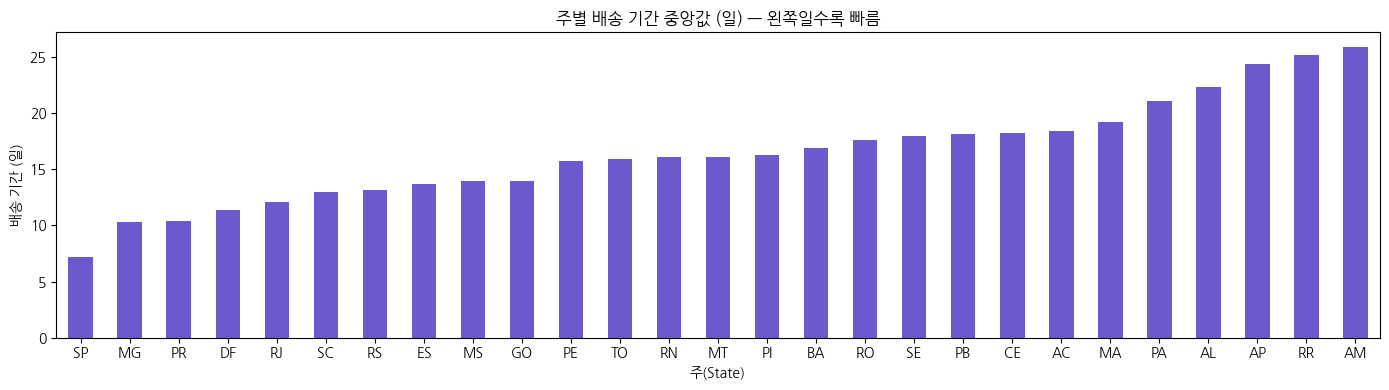

In [27]:
# 인사이트 10-2. 어디서? → 주(state)별 배송 기간 · 지연율 · 배송비

# 주문별 배송비 합계 (items : 상품 1개 = 1행 → 주문별로 합칩니다)
base["freight_total"] = base["order_id"].map(
    base_items.groupby("order_id")["freight_value"].sum()
)

region = base.groupby("customer_state").agg(
    주문수=("order_id", "count"),
    배송기간_중앙값=("delivery_days", "median"),
    지연율=("is_late", "mean"),
    평균배송비=("freight_total", "mean"),
    평균리뷰=("review_score", "mean"),
).sort_values("배송기간_중앙값")

print(region.round(2))

region["배송기간_중앙값"].plot(kind="bar", figsize=(14, 4), color="slateblue")
plt.title("주별 배송 기간 중앙값 (일) — 왼쪽일수록 빠름")
plt.xlabel("주(State)")
plt.ylabel("배송 기간 (일)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**해석 — 언제? (성수기)**
- 그 외 달의 지연율은 대부분 1~8%대지만, **2017-11(14.3%)**, **2018-02(16.0%)**, **2018-03(21.4%)**에 크게 오릅니다.
- 11월은 블랙프라이데이로 주문이 한꺼번에 몰린 때입니다(인사이트 6). 물량이 몰리면 물류가 감당하지 못합니다.
- 2~3월은 주문 수가 평소 수준인데도 지연이 가장 심했습니다. 원인은 **이 데이터만으로는 알 수 없습니다.** (날씨·물류 사정 등 외부 정보 확인 필요)
- 2018-08은 데이터가 끝나는 시점까지 배송이 끝난 주문만 남아 있어 해석에 주의합니다.

**해석 — 어디서? (원거리)**
- SP는 중앙값 **7.2일**, 평균 배송비 **R$17.3**로 가장 빠르고 쌉니다.
- 북부의 AM·RR·AP는 **24~26일**, PA는 21일, 북동부의 AL·MA는 **19~22일**이 걸립니다. 배송비는 R$37~49 수준으로 SP의 2배가 넘습니다.
- 지연율도 AL(24%)·MA(20%)는 SP(6%)의 3~4배이고, 평균 리뷰도 낮습니다(AL 3.86, MA 3.83).
- 단, RR(40건)·AP(67건)·AC(80건)는 주문 수가 적어 지연율이 들쭉날쭉합니다.

**비즈니스 시사점**
- 인사이트 2(남동부 집중)의 이면입니다. 다른 지역이 적게 사는 이유 중 하나가 **느리고 비싼 배송**입니다.
- 북동부 거점 물류센터나 지역 판매자 유치가 새 시장을 여는 열쇠가 될 수 있습니다.
- 성수기에는 도착 예정일을 넉넉하게 안내하고, 물류 인력을 미리 늘립니다.
- 🔗 PART 8 판매자 유형 분석에서 지연이 판매자 출고 구간과 택배 운송 구간 중 어디서 생기는지 확인합니다.
- 인사이트 9와 합치면, 배송이 리뷰를 깎고 리뷰가 재구매(인사이트 1)를 막는 **연결 고리**가 보입니다.

---

## 마무리 정리

| 확인할 내용 | 설명 |
|---|---|
| 이 파트의 핵심 | 그래프와 집계로 데이터의 패턴을 파악합니다. |
| 집계 단위 | 주문은 `orders`, 상품은 `items`, 매출은 `pay`로 셉니다. `df`를 그대로 더하면 중복 계산됩니다. |
| 분석 기간 | 데이터 앞뒤의 빈 구간을 빼야 합니다. (2017-01-05 ~ 2018-08-29, 배송 완료 주문) |
| 주의사항 | 그래프 급락 = 실제 매출 하락이 아닐 수 있습니다. 원인을 항상 확인하세요. |
| 공정한 비교 | 같은 기간끼리, 특별 이벤트를 고려해서 비교합니다. |
| 다음 단계 | PART 6에서 상품 특징으로 비슷한 상품을 찾아 추천합니다. |

### 인사이트 10가지 요약
| 번호 | 인사이트 | 핵심 숫자 |
|---|---|---|
| 1 | 고객 대부분이 한 번 사고 떠난다 | 1회 구매 고객 97.0% |
| 2 | 고객은 남동부 3개 주에 몰려 있다 | SP·RJ·MG 주문 66.6% |
| 3 | 신용카드 할부가 구매의 기본이다 | 신용카드 75.5%, 그중 할부 66.8% |
| 4 | '보통 주문'은 평균보다 훨씬 작다 | 평균 R$160 vs 중앙값 R$105 |
| 5 | 성장은 객단가가 아니라 주문 수에서 왔다 | 주문 2.40배, 객단가 +1.4% |
| 6 | 블랙프라이데이 — 그리고 공정한 비교의 중요성 | 2017-11-24 하루 1,147건 (평소 7.8배) |
| 7 | 평일 낮에 사고, 새벽·주말에는 덜 산다 | 10~16시 45.2%, 0~5시 4.8% (단, 일요일 저녁은 높음) |
| 8 | 많이 팔리는 것과 돈이 되는 것은 다르다 | watches_gifts 개수 7위 → 매출 2위, 상위 17개가 매출 80% |
| 9 | 배송이 늦으면 리뷰가 무너진다 | 평균 리뷰 4.30 → 2.57, 1점 비율 7배 |
| 10 | 성수기와 먼 지역에서 배송이 늦어진다 | 지연율 최고 21.4%(2018-03, 평균 8.1%), SP 7.2일 vs 북부 24~26일 |

---
## 인사이트를 실행으로 — 한 장 요약

| 번호 | 인사이트 | 제안하는 행동 | 측정할 지표(KPI) |
|---|---|---|---|
| 1 | 재구매율 약 3% | 첫 구매 후 재구매 쿠폰 · 알림 | 재구매율, 90일 내 재구매 고객 수 |
| 2 | 남동부 3개 주에 약 67% (66.6%) | 지역별 마케팅 · 물류 배분 | 주별 고객 수 · 침투율 |
| 3 | 카드 할부가 기본 (카드 75.5%, 그중 할부 66.8%) | 무이자 할부 프로모션 | 할부 결제 비율, 고가 상품 전환율 |
| 4 | 평균 R$160 · 중앙값 R$105 | 프로모션 기준 금액을 분포로 설정 | 중앙값 객단가 |
| 5 | 성장 = 주문 수 (주문 2.40배, 객단가 +1.4%) | 유입 채널 유지 + 재구매 개선 | 월 주문 수, 신규 고객 수 |
| 6 | 블랙프라이데이 폭증 (평소 7.8배) | 성수기 재고 · 물류 사전 증원 | 성수기 일 주문 수 · 지연율 |
| 7 | 평일 낮 집중 (10~16시 45.2%) | 알림 · 타임 세일 · 상담 인력 시간대 조정 | 시간대별 전환율 |
| 8 | 수량 ≠ 매출, 상위 17개가 매출 80% | 핵심 카테고리 집중 관리 | 카테고리별 매출 · 점유율 |
| 9 | 지연 시 리뷰 4.3 → 2.6 | 지연 위험 주문 사전 안내 · 보상 | 지연율, 평균 리뷰, 1점 비율 |
| 10 | 성수기 · 원거리 지연 (최고 21.4%, 북부 24~26일) | 예정일 현실화 · 지역 거점 | 월별 · 주별 지연율, 배송 중앙값 |